# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='blue'> Profesor: Alejandro I. Trejo-Castro</font>

### 4.2. Prueba de hipótesis

*Bienvenidos* a este jupyter notebook que nos será de utilidad para analizar la presión arterial de 120 pacientes, registrada antes y después. Cada fila corresponde a una persona: las dos mediciones están emparejadas.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

In [1]:
import warnings
warnings.filterwarnings("ignore")

#Cargar bibliotecas esenciales para el análisis de datos
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("seaborn:", sns.__version__)
print("Matplotlib:", matplotlib.__version__)

import scipy.stats as stats
np.random.seed(42)
sns.set_theme(style="whitegrid")

NumPy: 1.26.4
pandas: 3.0.6
seaborn: 0.13.2
Matplotlib: 3.11.2


#### ¿Hay evidencia estadística de un cambio en la presión arterial media entre ambas mediciones?

In [2]:
data = pd.read_csv("blood-pressure.csv")
data.head()

,patient,sex,agegrp,bp_before,bp_after
0,1,Male,30-45,143,153
1,2,Male,30-45,163,170
2,3,Male,30-45,153,168
3,4,Male,30-45,153,142
4,5,Male,30-45,146,141


#### ¿Son dos grupos diferentes o son las mismas personas medidas dos veces?

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   patient    120 non-null    int64
 1   sex        120 non-null    str  
 2   agegrp     120 non-null    str  
 3   bp_before  120 non-null    int64
 4   bp_after   120 non-null    int64
dtypes: int64(3), str(2)
memory usage: 5.9 KB


In [4]:
data.describe()

,patient,bp_before,bp_after
count,120.000000,120.000000,120.000000
mean,60.500000,156.450000,151.358333
std,34.785054,11.389845,14.177622
min,1.000000,138.000000,125.000000
25%,30.750000,147.000000,140.750000
50%,60.500000,154.500000,149.500000
75%,90.250000,164.000000,161.000000
max,120.000000,185.000000,185.000000


In [5]:
data.describe(include="str")

,sex,agegrp
count,120,120
unique,2,3
top,Male,30-45
freq,60,40


#### El promedio bajó. ¿Eso significa que la presión bajo en todos los pacientes?

In [6]:
data["cambio"] = data["bp_after"] - data["bp_before"]

data[["patient", "bp_before", "bp_after", "cambio"]].head()

,patient,bp_before,bp_after,cambio
0,1,143,153,10
1,2,163,170,7
2,3,153,168,15
3,4,153,142,-11
4,5,146,141,-5


In [7]:
data[["patient", "bp_before", "bp_after", "cambio"]].sort_values(by="cambio", ascending=False).head()

,patient,bp_before,bp_after,cambio
27,28,142,183,41
33,34,148,184,36
56,57,147,176,29
72,73,141,168,27
113,114,151,177,26


In [8]:
data[["patient", "bp_before", "bp_after", "cambio"]].sort_values(by="cambio", ascending=True).head()

,patient,bp_before,bp_after,cambio
38,39,185,140,-45
31,32,184,139,-45
17,18,176,134,-42
9,10,158,125,-33
80,81,157,127,-30


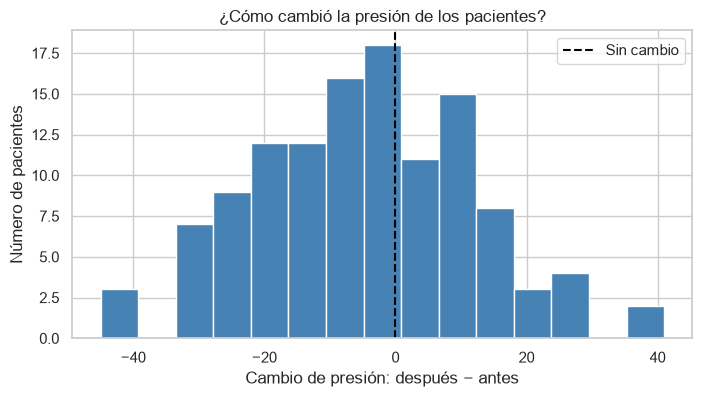

In [9]:
plt.figure(figsize=(8, 4))

plt.hist(data["cambio"], bins=15, color="steelblue",
         edgecolor="white")
plt.axvline(0, color="black", linestyle="--", label="Sin cambio")

plt.xlabel("Cambio de presión: después − antes")
plt.ylabel("Número de pacientes")
plt.title("¿Cómo cambió la presión de los pacientes?")
plt.legend()
plt.show()

In [10]:
disminuyo = data["cambio"] < 0

print(f"Pacientes cuya presión disminuyó: {disminuyo.sum()}")
print(f"Porcentaje: {disminuyo.mean():.1%}")
print(f"Cambio promedio: {data['cambio'].mean():.2f}")

Pacientes cuya presión disminuyó: 73
Porcentaje: 60.8%
Cambio promedio: -5.09


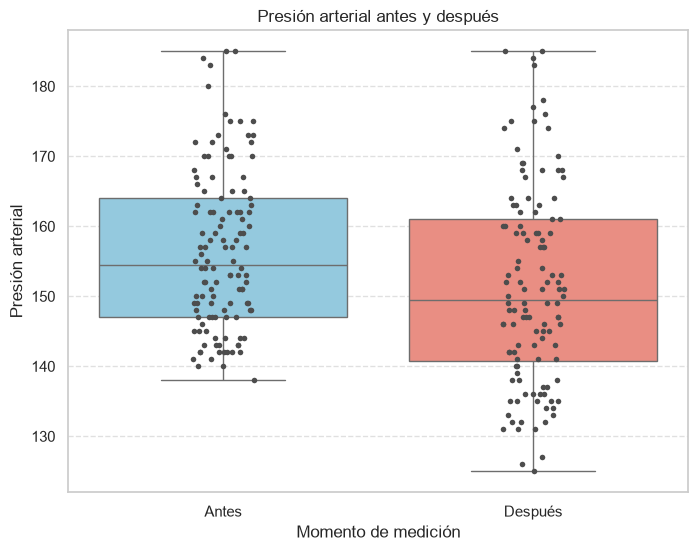

In [11]:
# Comparar las distribuciones antes y después: cada punto es una medición.
# Este gráfico no muestra qué puntos corresponden al mismo paciente.
plt.figure(figsize=(8, 6))
sns.boxplot(data=data[['bp_before', 'bp_after']], palette=["skyblue", "salmon"])
sns.stripplot(data=data[['bp_before', 'bp_after']], color=".3", size=4, jitter=True)
plt.xlabel('Momento de medición')
plt.ylabel('Presión arterial')
plt.title('Presión arterial antes y después')
plt.xticks([0, 1], ['Antes', 'Después'])
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
plt.show()

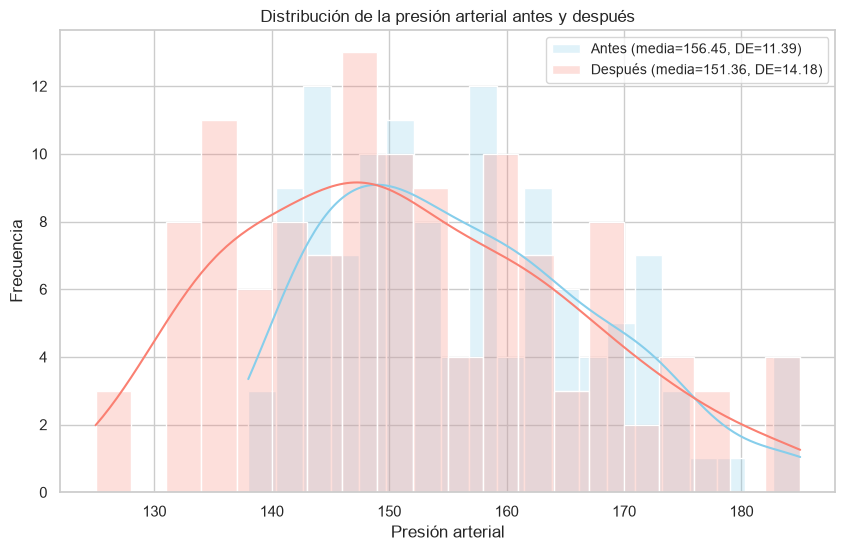

In [12]:
bp_bef = np.array(data['bp_before'])
bp_af = np.array(data['bp_after'])

# Calcular las etiquetas a partir de los datos; DE = desviación estándar muestral.
plt.figure(figsize=(10, 6))
sns.histplot(bp_bef, color="skyblue",
             label=f"Antes (media={bp_bef.mean():.2f}, DE={bp_bef.std(ddof=1):.2f})",
             alpha=0.25, kde=True, bins=20)
sns.histplot(bp_af, color="salmon",
             label=f"Después (media={bp_af.mean():.2f}, DE={bp_af.std(ddof=1):.2f})",
             alpha=0.25, kde=True, bins=20)
plt.xlabel('Presión arterial')
plt.ylabel('Frecuencia')
plt.title('Distribución de la presión arterial antes y después')
plt.legend(fontsize='small')
plt.show()

#### Prueba t de una muestra: presión antes de la segunda medición.
#### Pregunta: ¿la media poblacional de la presión inicial difiere de 156?

In [13]:
from scipy.stats import ttest_1samp

# Seleccionar la presión inicial de cada paciente.
bp_bef = np.array(data['bp_before'])
print('Presión antes:', bp_bef)

# Calcular la media observada y compararla con la referencia de 156.
bp_bef_mean = np.mean(bp_bef)
print(f'Media de la presión antes: {bp_bef_mean:.2f}')

Presión antes: [143 163 153 153 146 150 148 153 153 158 149 173 165 145 143 152 141 176
 143 162 149 156 151 159 164 154 152 142 162 155 175 184 167 148 170 159
 149 140 185 160 157 158 162 160 180 155 172 157 171 170 175 175 172 173
 170 164 147 154 172 162 152 147 144 144 158 147 154 151 149 138 162 157
 141 167 147 143 142 166 147 142 157 170 150 150 167 154 143 157 149 161
 142 162 144 142 159 140 144 142 145 145 168 142 147 148 162 170 173 151
 155 163 183 159 148 151 165 152 161 165 149 185]
Media de la presión antes: 156.45


In [14]:
# Prueba t bilateral de una muestra con media de referencia de 156.
tset, pval = ttest_1samp(bp_bef, 156)
print(f"Estadístico t: {tset:.4f}")
print(f"Valor p: {pval:.4g}")

# Comparar el valor p con el nivel de significancia α = 0.05.
if pval < 0.05:
    print("Rechazamos H₀: hay evidencia de que la media inicial difiere de 156.")
else:
    print("No rechazamos H₀: no hay evidencia suficiente de que la media inicial difiera de 156.")

Estadístico t: 0.4328
Valor p: 0.6659
No rechazamos H₀: no hay evidencia suficiente de que la media inicial difiera de 156.


#### Prueba t de dos muestras independientes: comparación didáctica
#### Pregunta metodológica: ¿qué resultado produce una prueba que trata las mediciones como si pertenecieran a grupos independientes?

In [15]:
from scipy.stats import ttest_ind

# Seleccionar las dos mediciones conservando el orden de los pacientes.
bp_bef = np.array(data['bp_before'])
bp_af = np.array(data['bp_after'])
print("Presión antes:", bp_bef)
print("Presión después:", bp_af)

# Calcular las medias de ambas mediciones.
bp_bef_m = np.mean(bp_bef)
bp_af_m = np.mean(bp_af)
print(f"Media antes: {bp_bef_m:.2f}")
print(f"Media después: {bp_af_m:.2f}")

# Calcular las desviaciones estándar muestrales (ddof=1).
bp_bef_std = np.std(bp_bef, ddof=1)
bp_af_std = np.std(bp_af, ddof=1)
print(f"Desviación estándar antes: {bp_bef_std:.2f}")
print(f"Desviación estándar después: {bp_af_std:.2f}")

Presión antes: [143 163 153 153 146 150 148 153 153 158 149 173 165 145 143 152 141 176
 143 162 149 156 151 159 164 154 152 142 162 155 175 184 167 148 170 159
 149 140 185 160 157 158 162 160 180 155 172 157 171 170 175 175 172 173
 170 164 147 154 172 162 152 147 144 144 158 147 154 151 149 138 162 157
 141 167 147 143 142 166 147 142 157 170 150 150 167 154 143 157 149 161
 142 162 144 142 159 140 144 142 145 145 168 142 147 148 162 170 173 151
 155 163 183 159 148 151 165 152 161 165 149 185]
Presión después: [153 170 168 142 141 147 133 141 131 125 164 159 135 159 153 126 162 134
 136 150 168 155 136 132 160 160 136 183 152 162 151 139 175 184 151 171
 157 159 140 174 167 158 168 159 153 164 169 148 185 163 146 160 175 163
 185 146 176 147 161 164 149 142 146 138 131 145 134 135 131 135 133 135
 168 144 147 151 149 147 149 135 127 150 138 147 157 146 148 136 146 132
 145 132 157 140 137 154 169 145 137 143 178 141 149 148 138 143 167 158
 152 154 161 143 159 177 142 152 152 174 1

In [16]:
# Ejemplo didáctico: esta prueba ignora el emparejamiento de los pacientes.
ttest, pval = ttest_ind(bp_bef, bp_af)
print(f"Estadístico t: {ttest:.4f}")
print(f"Valor p: {pval:.4g}")

# Comparar el valor p con el nivel de significancia α = 0.05.
if pval < 0.05:
    print("Rechazamos H₀: bajo el supuesto de independencia, habría evidencia de medias diferentes.")
else:
    print("No rechazamos H₀: bajo el supuesto de independencia, no habría evidencia suficiente de medias diferentes.")

Estadístico t: 3.0670
Valor p: 0.002412
Rechazamos H₀: bajo el supuesto de independencia, habría evidencia de medias diferentes.


#### Prueba t de muestras pareadas: respuesta a la pregunta de la práctica
#### ¿hay evidencia de un cambio medio entre las dos mediciones de los mismos pacientes?

In [17]:
# Prueba t bilateral pareada: comparar cada paciente consigo mismo.
ttest, pval = stats.ttest_rel(bp_bef, bp_af)
print(f"Estadístico t: {ttest:.4f}")
print(f"Valor p: {pval:.4g}")

# Comparar el valor p con el nivel de significancia α = 0.05.
if pval < 0.05:
    print("Rechazamos H₀: hay evidencia de un cambio medio entre las dos mediciones.")
else:
    print("No rechazamos H₀: no hay evidencia suficiente de un cambio medio entre las dos mediciones.")

Estadístico t: 3.3372
Valor p: 0.00113
Rechazamos H₀: hay evidencia de un cambio medio entre las dos mediciones.


#### Prueba z de una muestra: aproximación para la presión inicial
#### ¿la media poblacional de la presión inicial difiere de la referencia hipotética de 156?

In [18]:
# Prueba z bilateral de una muestra mediante aproximación normal.
from scipy import stats
from statsmodels.stats import weightstats as stests

ztest, pval = stests.ztest(bp_bef, x2=None, value=156)
print(f"Estadístico z: {ztest:.4f}")
print(f"Valor p: {pval:.4g}")

# Comparar el valor p con el nivel de significancia α = 0.05.
if pval < 0.05:
    print("Rechazamos H₀: con la aproximación normal, hay evidencia de que la media inicial difiere de 156.")
else:
    print("No rechazamos H₀: con la aproximación normal, no hay evidencia suficiente de que la media inicial difiera de 156.")

Estadístico z: 0.4328
Valor p: 0.6652
No rechazamos H₀: con la aproximación normal, no hay evidencia suficiente de que la media inicial difiera de 156.


#### Prueba z de dos muestras independientes: comparación didáctica

In [19]:
# Ejemplo didáctico: aproximación normal que ignora el emparejamiento.
ztest, pval = stests.ztest(bp_bef, bp_af, value=0, alternative="two-sided")
print(f"Estadístico z: {ztest:.4f}")
print(f"Valor p: {pval:.4g}")

# Comparar el valor p con el nivel de significancia α = 0.05.
if pval < 0.05:
    print("Rechazamos H₀: bajo el supuesto de independencia, habría evidencia de medias diferentes.")
else:
    print("No rechazamos H₀: bajo el supuesto de independencia, no habría evidencia suficiente de medias diferentes.")

Estadístico z: 3.0670
Valor p: 0.002162
Rechazamos H₀: bajo el supuesto de independencia, habría evidencia de medias diferentes.
